In [41]:
import pandas as pd

df = pd.read_csv('data/heart_disease.csv')

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Age                   9971 non-null   float64
 1   Gender                9981 non-null   str    
 2   Blood Pressure        9981 non-null   float64
 3   Cholesterol Level     9970 non-null   float64
 4   Exercise Habits       9975 non-null   str    
 5   Smoking               9975 non-null   str    
 6   Family Heart Disease  9979 non-null   str    
 7   Diabetes              9970 non-null   str    
 8   BMI                   9978 non-null   float64
 9   High Blood Pressure   9974 non-null   str    
 10  Low HDL Cholesterol   9975 non-null   str    
 11  High LDL Cholesterol  9974 non-null   str    
 12  Alcohol Consumption   7414 non-null   str    
 13  Stress Level          9978 non-null   str    
 14  Sleep Hours           9975 non-null   float64
 15  Sugar Consumption     9970 non-

### Filling missing data for both numeric and categorical data:

In [43]:
def clean_data(df):
    df=df.copy()
    numeric_columns = df.select_dtypes(include="number").columns
    category_columns = df.select_dtypes(exclude="number").columns

    df[numeric_columns] = df[numeric_columns].fillna(
        df[numeric_columns].median()
    )

    for column in category_columns:
        if df[column].isna().any():
            df[column] = df[column].fillna(df[column].mode().iloc[0])

    return df

print(clean_data(df).info())
print(f"Number of duplicated rows: {clean_data(df).duplicated().sum()}")

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Age                   10000 non-null  float64
 1   Gender                10000 non-null  str    
 2   Blood Pressure        10000 non-null  float64
 3   Cholesterol Level     10000 non-null  float64
 4   Exercise Habits       10000 non-null  str    
 5   Smoking               10000 non-null  str    
 6   Family Heart Disease  10000 non-null  str    
 7   Diabetes              10000 non-null  str    
 8   BMI                   10000 non-null  float64
 9   High Blood Pressure   10000 non-null  str    
 10  Low HDL Cholesterol   10000 non-null  str    
 11  High LDL Cholesterol  10000 non-null  str    
 12  Alcohol Consumption   10000 non-null  str    
 13  Stress Level          10000 non-null  str    
 14  Sleep Hours           10000 non-null  float64
 15  Sugar Consumption     10000 non

In [40]:
df.duplicated().sum()

np.int64(0)

In [39]:
df.tail(10)

,Age,Gender,Blood Pressure,Cholesterol Level,Exercise Habits,Smoking,Family Heart Disease,Diabetes,BMI,High Blood Pressure,...,High LDL Cholesterol,Alcohol Consumption,Stress Level,Sleep Hours,Sugar Consumption,Triglyceride Level,Fasting Blood Sugar,CRP Level,Homocysteine Level,Heart Disease Status
9990,55.0,Female,131.0,160.0,High,Yes,No,Yes,32.363462,No,...,No,Low,Medium,5.018783,Medium,267.0,129.0,0.603213,11.298252,Yes
9991,41.0,Female,160.0,241.0,Medium,No,Yes,Yes,39.346342,Yes,...,Yes,NaN,High,4.343666,Low,178.0,106.0,4.718864,14.219791,Yes
9992,68.0,Female,169.0,291.0,Medium,Yes,No,No,22.839718,No,...,No,Medium,Low,6.057509,High,299.0,142.0,3.321020,11.910244,Yes
9993,27.0,Female,153.0,188.0,Medium,No,No,Yes,28.173059,Yes,...,No,NaN,Medium,4.834842,High,300.0,118.0,6.216700,13.114808,Yes
9994,73.0,Female,144.0,191.0,Medium,Yes,Yes,Yes,39.459620,No,...,No,Medium,Low,7.549114,Medium,200.0,88.0,1.154904,8.021732,Yes
9995,25.0,Female,136.0,243.0,Medium,Yes,No,No,18.788791,Yes,...,Yes,Medium,High,6.834954,Medium,343.0,133.0,3.588814,19.132004,Yes
9996,38.0,Male,172.0,154.0,Medium,No,No,No,31.856801,Yes,...,Yes,NaN,High,8.247784,Low,377.0,83.0,2.658267,9.715709,Yes
9997,73.0,Male,152.0,201.0,High,Yes,No,Yes,26.899911,No,...,Yes,NaN,Low,4.436762,Low,248.0,88.0,4.408867,9.492429,Yes
9998,23.0,Male,142.0,299.0,Low,Yes,No,Yes,34.964026,Yes,...,Yes,Medium,High,8.526329,Medium,113.0,153.0,7.215634,11.873486,Yes
9999,38.0,Female,128.0,193.0,Medium,Yes,Yes,Yes,25.111295,No,...,Yes,High,Medium,5.659394,High,121.0,149.0,14.387810,6.208531,Yes


#### Visualizing the data

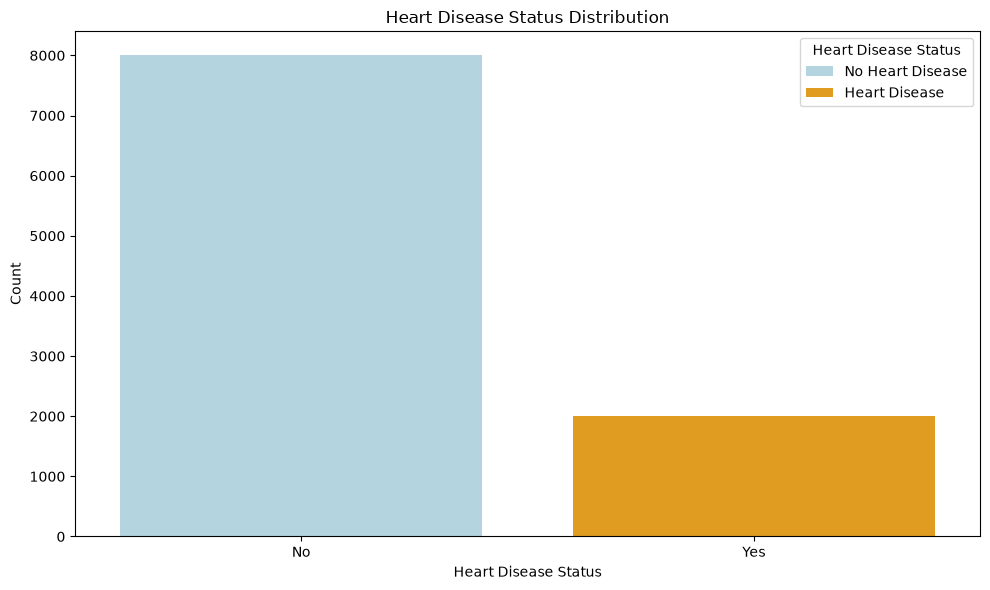

In [11]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6)) 
sns.countplot(x="Heart Disease Status", hue="Heart Disease Status", data=df, palette=["lightblue", "orange"])
plt.title("Heart Disease Status Distribution")
plt.legend(title="Heart Disease Status", labels=["No Heart Disease", "Heart Disease"])
plt.xlabel("Heart Disease Status")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

##### We use ensemble methods to handle the class imbalance in the dataset. We will use a Random Forest Classifier with balanced class weights to improve the model's performance on the minority class. SimpleImputer is used to handle missing values in both numeric and categorical features. The pipeline is constructed using ColumnTransformer to apply different preprocessing steps to numeric and categorical features separately. Finally, we split the data into training and testing sets, fit the model, and evaluate its performance using balanced accuracy score.

In [47]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer

X = df.drop('Heart Disease Status', axis=1)
y = df['Heart Disease Status']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

###We split the data into training and testing. Preprocess the training data and test on new and unsen dataset(test). we use RandomForestClassifier as the basemodel

In [48]:
numeric_features = X_train.select_dtypes(include="number").columns
categorical_features = X_train.select_dtypes(
    include=["object", "category", "string"]
).columns

numeric_pipeline = Pipeline(steps=[
    ("scale", StandardScaler()),
])
categorical_pipeline = Pipeline(steps=[
    ("encode", OneHotEncoder(handle_unknown="ignore")),
])
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features),
])

rf = RandomForestClassifier(random_state=42)
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", rf),
])

model.fit(X_train, y_train)
y_pred = model.predict(X_test)



In [49]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

print("Classification Report:")
print(classification_report(y_test, y_pred))
print("Accuracy Score:")
print(accuracy_score(y_test, y_pred))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Classification Report:
              precision    recall  f1-score   support

          No       0.80      1.00      0.89      2400
         Yes       0.00      0.00      0.00       600

    accuracy                           0.80      3000
   macro avg       0.40      0.50      0.44      3000
weighted avg       0.64      0.80      0.71      3000

Accuracy Score:
0.8
Confusion Matrix:
[[2400    0]
 [ 600    0]]


c:\Users\PC\Documents\mid-term\.midterm\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\PC\Documents\mid-term\.midterm\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\PC\Documents\mid-term\.midterm\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", 

In [50]:
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
)

labels = ["No", "Yes"]
y_test_binary = (y_test == "Yes").astype(int)

# Use the probability for the positive ("Yes") class.
yes_index = list(model.classes_).index("Yes")
y_score = model.predict_proba(X_test)[:, yes_index]

print("Classification report:")
print(classification_report(
    y_test, y_pred, labels=labels, zero_division=0
))

print(f"Accuracy:          {accuracy_score(y_test, y_pred):.3f}")
print(f"Balanced accuracy: {balanced_accuracy_score(y_test, y_pred):.3f}")
print(f"Average precision (PR-AUC): {average_precision_score(y_test_binary, y_score):.3f}")
print(f"ROC-AUC:           {roc_auc_score(y_test_binary, y_score):.3f}")

print("Confusion matrix (rows=true, columns=predicted; No, Yes):")
print(confusion_matrix(y_test, y_pred, labels=labels))

Classification report:
              precision    recall  f1-score   support

          No       0.80      1.00      0.89      2400
         Yes       0.00      0.00      0.00       600

    accuracy                           0.80      3000
   macro avg       0.40      0.50      0.44      3000
weighted avg       0.64      0.80      0.71      3000

Accuracy:          0.800
Balanced accuracy: 0.500
Average precision (PR-AUC): 0.198
ROC-AUC:           0.500
Confusion matrix (rows=true, columns=predicted; No, Yes):
[[2400    0]
 [ 600    0]]
